## Knowledge At Risk: Data Science Open Project 📖📚
## Jake, Helen, & Raji 🤖🤖🤖
## ASU Data Science and Analytics 💻🔱
## September 23, 2026 📅

### Description 📝

This notebook is a student demonstration for ASU’s Open Project Data Science: Book Banning event, scheduled for October 7, 2026, at Hayden Library. It uses descriptive analysis, visualizations, source verification, and text modeling to explore patterns in book challenges and examine how stated censorship reasons differ across books, music, and films.

# I. Data Inspection 🔎 and Cleaning 🧹

This dataset contains 84 censorship records: 21 books, 21 graphic novels/comics, 21 films, and 21 songs. We used an equal sample because music had only 21 individual tracks with complete, usable information. Keeping every category the same size prevents the much larger book dataset from dominating the visualizations. This sample is intended for comparing general censorship patterns across media, not measuring total censorship frequency.

In [2]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# locate the file(s)

# main worksheet - individual records and original descriptions
censorship_df = pd.read_excel("~/Downloads/Censorship_Visualization_Only_Dataset.xlsx")
# comparison worksheet - counts and percentages for each reason by medium
comparison = pd.read_excel("~/Downloads/Censorship_Visualization_Only_Dataset.xlsx", sheet_name="Reason Comparison")
# breadth worksheet - one versus multiple reason group
breadth = pd.read_excel("~/Downloads/Censorship_Visualization_Only_Dataset.xlsx", sheet_name="Reason Breadth")

In [5]:
# check dtypes
censorship_df.info()
print("")
comparison.info()
print("")
breadth.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Record ID                      84 non-null     object
 1   Title                          84 non-null     object
 2   Creator                        84 non-null     object
 3   Medium                         84 non-null     object
 4   Original Reason                84 non-null     object
 5   Source Dataset                 84 non-null     object
 6   Source Reference               84 non-null     object
 7   Sexual content                 84 non-null     int64 
 8   LGBTQIA+ themes                84 non-null     int64 
 9   Language                       84 non-null     int64 
 10  Violence and harm              84 non-null     int64 
 11  Political and social identity  84 non-null     int64 
 12  Religion                       84 non-null     int64 
 13  Other g

In [6]:
# check for duplicates
censorship_df.duplicated().sum()
print("")
comparison.duplicated().sum
print("")
breadth.duplicated().sum()

np.int64(0)

In [8]:
# check for rows
print((censorship_df == '?').sum(axis=1))
print("")
print((comparison == '?').sum(axis=1))
print("")
print((breadth == '?').sum(axis=1))

0     0
1     0
2     0
3     0
4     0
     ..
79    0
80    0
81    0
82    0
83    0
Length: 84, dtype: int64

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
26    0
27    0
dtype: int64

0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
dtype: int64


In [13]:
# check for columns
print((censorship_df == '?').sum(axis=0))

Record ID                        0
Title                            0
Creator                          0
Medium                           0
Original Reason                  0
Source Dataset                   0
Source Reference                 0
Sexual content                   0
LGBTQIA+ themes                  0
Language                         0
Violence and harm                0
Political and social identity    0
Religion                         0
Other grounds                    0
Reason Group Count               0
Reason Breadth                   0
dtype: int64


In [9]:
# check for unique values
censorship_df.nunique()
print("")
comparison.nunique()
print("")
breadth.nunique()

Medium            4
Reason Breadth    2
Count             6
Denominator       1
Share             6
dtype: int64

# II. Analysis & Visualizations 📊

## What are the main censorship reasons for each medium?

In [10]:
# Category oder
medium_order = ["Book", "Graphic Novel/Comic", "Film", "Music"]

reason_order = [
    "Sexual content",
    "LGBTQIA+ themes",
    "Language",
    "Violence and harm",
    "Political and social identity",
    "Religion",
    "Other grounds"
]

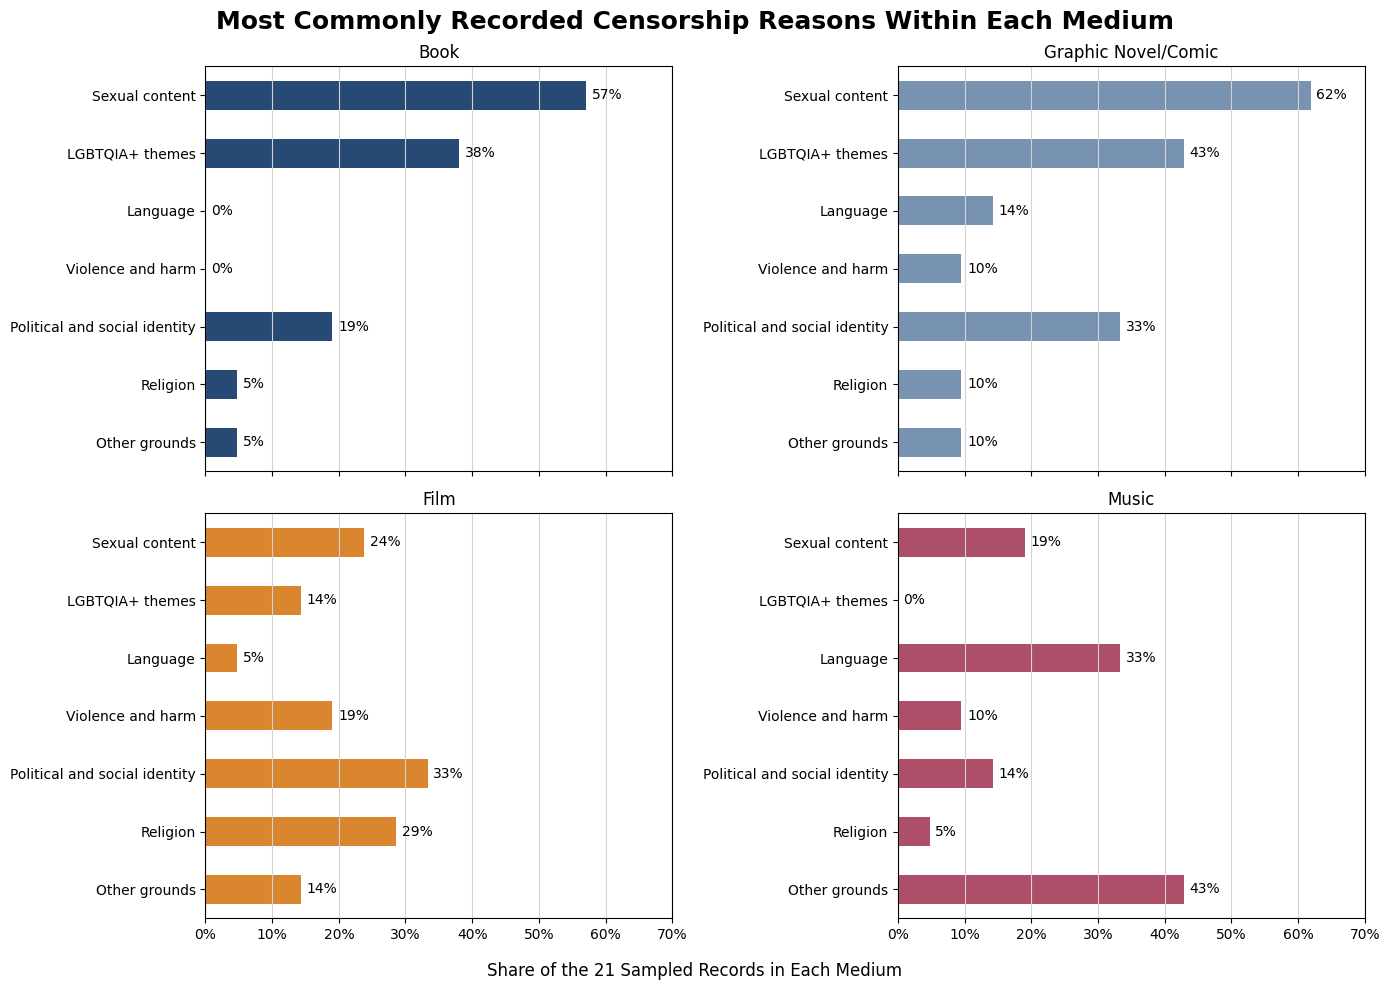

In [13]:
from matplotlib.ticker import PercentFormatter

# Prepare the data for each medium
book_reasons = comparison[comparison["Medium"] == "Book"].set_index("Reason Group").reindex(reason_order).iloc[::-1]

comic_reasons = comparison[comparison["Medium"] == "Graphic Novel/Comic"].set_index("Reason Group").reindex(reason_order).iloc[::-1]

film_reasons = comparison[comparison["Medium"] == "Film"].set_index("Reason Group").reindex(reason_order).iloc[::-1]

music_reasons = comparison[comparison["Medium"] == "Music"].set_index("Reason Group").reindex(reason_order).iloc[::-1]


# Create four bar charts
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)

book_reasons["Share"].plot.barh(ax=axes[0, 0], color="#264A73")
comic_reasons["Share"].plot.barh(ax=axes[0, 1], color="#7892B1")
film_reasons["Share"].plot.barh(ax=axes[1, 0], color="#D9862F")
music_reasons["Share"].plot.barh(ax=axes[1, 1], color="#AD4F68")


# Add chart titles
axes[0, 0].set_title("Book")
axes[0, 1].set_title("Graphic Novel/Comic")
axes[1, 0].set_title("Film")
axes[1, 1].set_title("Music")


# Add percentage labels
axes[0, 0].bar_label(axes[0, 0].containers[0], labels=[f"{value:.0%}" for value in book_reasons["Share"]], padding=4)

axes[0, 1].bar_label(axes[0, 1].containers[0], labels=[f"{value:.0%}" for value in comic_reasons["Share"]], padding=4)

axes[1, 0].bar_label(axes[1, 0].containers[0], labels=[f"{value:.0%}" for value in film_reasons["Share"]], padding=4)

axes[1, 1].bar_label(axes[1, 1].containers[0], labels=[f"{value:.0%}" for value in music_reasons["Share"]], padding=4)


# Format the charts
for ax in axes.flat:
    ax.set_xlim(0, 0.70)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="x", color="lightgray")
    ax.grid(axis="y", visible=False)


# Add the main title and final label
fig.suptitle(
    "Most Commonly Recorded Censorship Reasons Within Each Medium",
    fontsize=18,
    fontweight="bold"
)
fig.supxlabel("Share of the 21 Sampled Records in Each Medium")
plt.tight_layout()
plt.show()

### Figure 1: Main Censorship Reasons

How to read the chart: Each panel represents one medium. Longer bars indicate that a censorship reason appeared in a larger percentage of that medium’s 21 records.

What it shows: Sexual content was the most common recorded reason for Books and Graphic Novels/Comics. Film objections were more evenly divided among several reasons. Music had more objections related to language and other medium-specific concerns.

## How does each medium differ from books?

In [14]:
# Prepare the differences from Books

comic_difference = comparison[comparison["Medium"] == "Graphic Novel/Comic"].set_index("Reason Group").reindex(reason_order).iloc[::-1]

film_difference = comparison[comparison["Medium"] == "Film"].set_index("Reason Group").reindex(reason_order).iloc[::-1]

music_difference = comparison[comparison["Medium"] == "Music"].set_index("Reason Group").reindex(reason_order).iloc[::-1]

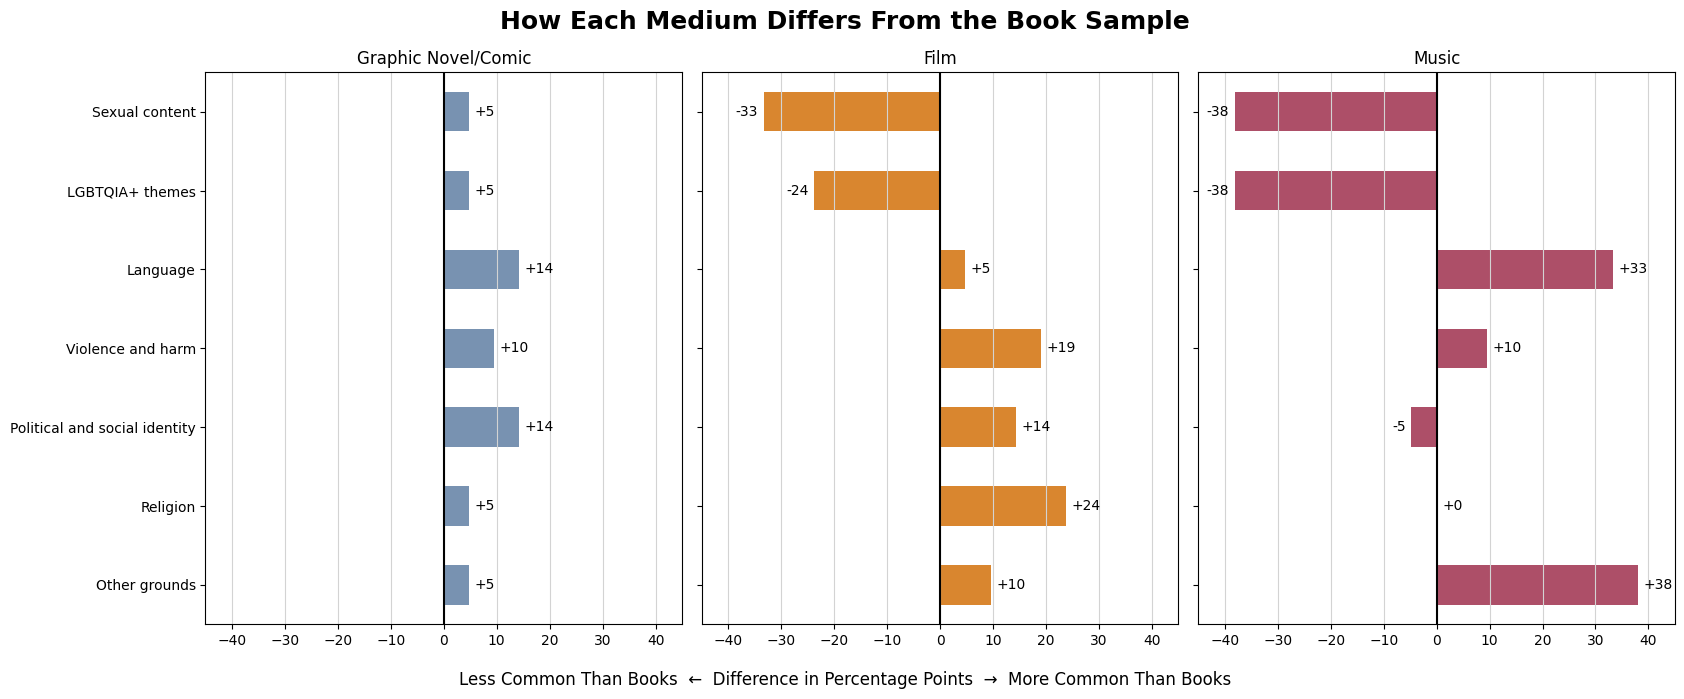

In [15]:
# Create three bar charts

fig, axes = plt.subplots(1, 3, figsize=(17, 7), sharex=True, sharey=True)

comic_difference["Difference from Books (pp)"].plot.barh(
    ax=axes[0],
    color="#7892B1"
)

film_difference["Difference from Books (pp)"].plot.barh(
    ax=axes[1],
    color="#D9862F"
)

music_difference["Difference from Books (pp)"].plot.barh(
    ax=axes[2],
    color="#AD4F68"
)


# Add chart titles
axes[0].set_title("Graphic Novel/Comic")
axes[1].set_title("Film")
axes[2].set_title("Music")


# Add numbers to the bars
axes[0].bar_label(
    axes[0].containers[0],
    labels=[f"{value:+.0f}" for value in comic_difference["Difference from Books (pp)"]],
    padding=4
)

axes[1].bar_label(
    axes[1].containers[0],
    labels=[f"{value:+.0f}" for value in film_difference["Difference from Books (pp)"]],
    padding=4
)

axes[2].bar_label(
    axes[2].containers[0],
    labels=[f"{value:+.0f}" for value in music_difference["Difference from Books (pp)"]],
    padding=4
)


# Format the charts
for ax in axes:
    ax.axvline(0, color="black")
    ax.set_xlim(-45, 45)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(axis="x", color="lightgray")
    ax.grid(axis="y", visible=False)


# Add the main title and final label
fig.suptitle(
    "How Each Medium Differs From the Book Sample",
    fontsize=18,
    fontweight="bold"
)

fig.supxlabel(
    "Less Common Than Books  ←  Difference in Percentage Points  →  More Common Than Books"
)

plt.tight_layout()
plt.show()

### Figure 2: Differences From Books

How to read the chart: The center line represents the Book sample. Bars pointing right show that a reason was more common than in Books. Bars pointing left show that it was less common. The numbers represent percentage-point differences.

What it shows: Graphic Novels/Comics had the most similar pattern to Books. Films had more objections involving religion and violence. Music had more objections involving language and other grounds but fewer involving sexual content and LGBTQIA+ themes.

## Which media have more records with multiple censorship reason groups?

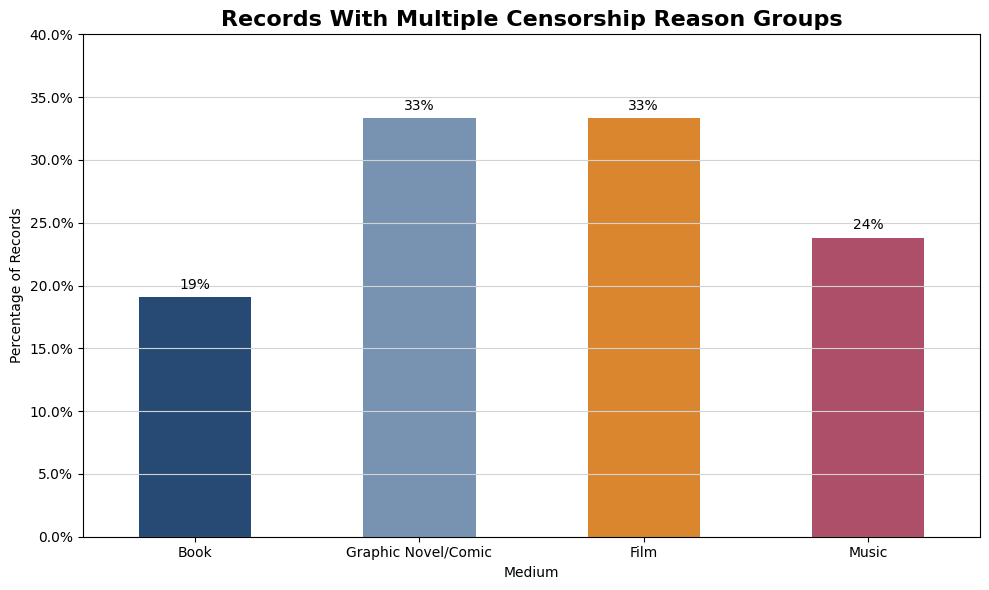

In [19]:
# Select records with multiple reason groups
multiple_reasons = breadth[
    breadth["Reason Breadth"] == "Multiple groups"
].set_index("Medium").reindex([
    "Book",
    "Graphic Novel/Comic",
    "Film",
    "Music"
])


# Create a bar chart
ax = multiple_reasons["Share"].plot.bar(
    figsize=(10, 6),
    color=["#264A73", "#7892B1", "#D9862F", "#AD4F68"]
)


# Add percentage labels
ax.bar_label(
    ax.containers[0],
    labels=[f"{value:.0%}" for value in multiple_reasons["Share"]],
    padding=4
)

# Add labels
plt.title(
    "Records With Multiple Censorship Reason Groups",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Medium")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=0)

ax.set_ylim(0, 0.40)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", color="lightgray")
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

### Figure 3: Multiple Censorship Reasons

How to read the chart: Each bar shows the percentage of records containing more than one censorship reason group. A taller bar means multiple objections were documented more often within that medium’s sample.

What it shows: Graphic Novels/Comics and Films had the highest percentage at 33%. Music followed at 24%, while Books had the lowest percentage at 19%.

### Important Note

These findings describe our balanced sample of 21 records per medium. They do not represent every censorship case or show which medium is censored most often.

# III. Cross-Media Similarity Finder 
# (Content-Based Recommendation Algorithm) 📜

In [20]:
# Select the censorship reason columns

reason_columns = [
    "Sexual content",
    "LGBTQIA+ themes",
    "Language",
    "Violence and harm",
    "Political and social identity",
    "Religion",
    "Other grounds"
]

reason_data = censorship_df[reason_columns]

reason_data.head()

,Sexual content,LGBTQIA+ themes,Language,Violence and harm,Political and social identity,Religion,Other grounds
0,1,0,0,0,0,1,0
1,1,1,0,0,1,0,0
2,1,0,0,0,0,0,0
3,0,1,0,0,0,0,0
4,0,1,0,0,0,0,0


In [22]:
# Calculate Jaccard similarity

from sklearn.metrics import pairwise_distances

similarity_matrix = 1 - pairwise_distances(
    reason_data.to_numpy(dtype=bool),
    metric="jaccard"
)

pd.DataFrame(similarity_matrix).iloc[:5, :5]

,0,1,2,3,4
0,1.00,0.250000,0.500000,0.000000,0.000000
1,0.25,1.000000,0.333333,0.333333,0.333333
2,0.50,0.333333,1.000000,0.000000,0.000000
3,0.00,0.333333,0.000000,1.000000,1.000000
4,0.00,0.333333,0.000000,1.000000,1.000000


In [23]:
# Display titles available for the recommendation system

censorship_df[["Title", "Medium"]].head(20)

,Title,Medium
0,Rogue Wave,Book
1,The Porcupine of Truth,Book
2,Grave Mercy,Book
3,Equality & Diversity,Book
4,When You Trap a Tiger,Book
5,Numbers,Book
6,A Shot at Normal,Book
7,The Neon Rain,Book
8,The Leftovers,Book
9,Courting Samira,Book


In [24]:
# Select a title
selected_title = "Rogue Wave"

selected_index = censorship_df.index[
    censorship_df["Title"] == selected_title
][0]

selected_medium = censorship_df.loc[selected_index, "Medium"]

In [25]:
# Find similar records from other media
recommendations = censorship_df[["Title", "Creator", "Medium"]].copy()

recommendations["Similarity"] = similarity_matrix[selected_index]

recommendations = recommendations[
    recommendations["Medium"] != selected_medium
].sort_values(
    "Similarity",
    ascending=False
).head(10)

recommendations

,Title,Creator,Medium,Similarity
27,Spy x Family. 5,Tatsuya Endō,Graphic Novel/Comic,1.0
66,Blurred Lines,Robin Thicke,Music,0.5
75,WAP,Cardi B & Megan Thee Stallion,Music,0.5
41,Roll Call: D&D Dungeon Club v.1,Lee Knox Ostertag,Graphic Novel/Comic,0.5
39,The Great and Secret Show,Clive Barker,Graphic Novel/Comic,0.5
50,The Last Temptation of Christ,Martin Scorsese,Film,0.5
37,"JoJo's Bizarre Adventure: Phantom Blood, Vol. 1",Hirohiko Araki,Graphic Novel/Comic,0.5
22,Wonder Woman: Tempest Tossed,Laurie Halse Anderson,Graphic Novel/Comic,0.5
35,A Dangerous Woman: The Graphic Biography of Em...,Sharon Rudahl,Graphic Novel/Comic,0.5
34,Skim,Mariko Tamaki,Graphic Novel/Comic,0.5


In [26]:
# Show the selected title's censorship reasons
selected_reasons = reason_data.columns[
    reason_data.loc[selected_index] == 1
].tolist()

print("Selected title:", selected_title)
print("Recorded reasons:", ", ".join(selected_reasons))

Selected title: Rogue Wave
Recorded reasons: Sexual content, Religion


In [29]:
# Create recommendations from every other medium

all_recommendations = censorship_df[["Title", "Creator", "Medium"]].copy()

all_recommendations["Similarity"] = similarity_matrix[selected_index]

all_recommendations = all_recommendations[
    all_recommendations["Medium"] != selected_medium
]

all_recommendations["Shared Reasons"] = reason_data.loc[
    all_recommendations.index
].multiply(
    reason_data.loc[selected_index]
).apply(
    lambda row: ", ".join(row.index[row == 1]),
    axis=1
)

all_recommendations = all_recommendations.sort_values(
    ["Medium", "Similarity"],
    ascending=[True, False]
)

top_recommendations = all_recommendations.groupby(
    "Medium"
).head(3).copy()

top_recommendations["Match"] = top_recommendations[
    "Similarity"
].map("{:.0%}".format)

top_recommendations[
    ["Title", "Creator", "Medium", "Shared Reasons", "Match"]
]

,Title,Creator,Medium,Shared Reasons,Match
43,Life of Brian,Terry Jones,Film,Religion,50%
50,The Last Temptation of Christ,Martin Scorsese,Film,Religion,50%
53,Noah,Darren Aronofsky,Film,Religion,50%
27,Spy x Family. 5,Tatsuya Endō,Graphic Novel/Comic,"Sexual content, Religion",100%
22,Wonder Woman: Tempest Tossed,Laurie Halse Anderson,Graphic Novel/Comic,Sexual content,50%
23,The Attack,Loïc Dauvillier,Graphic Novel/Comic,Sexual content,50%
66,Blurred Lines,Robin Thicke,Music,Sexual content,50%
68,Up & Down,EXID,Music,Sexual content,50%
75,WAP,Cardi B & Megan Thee Stallion,Music,Sexual content,50%


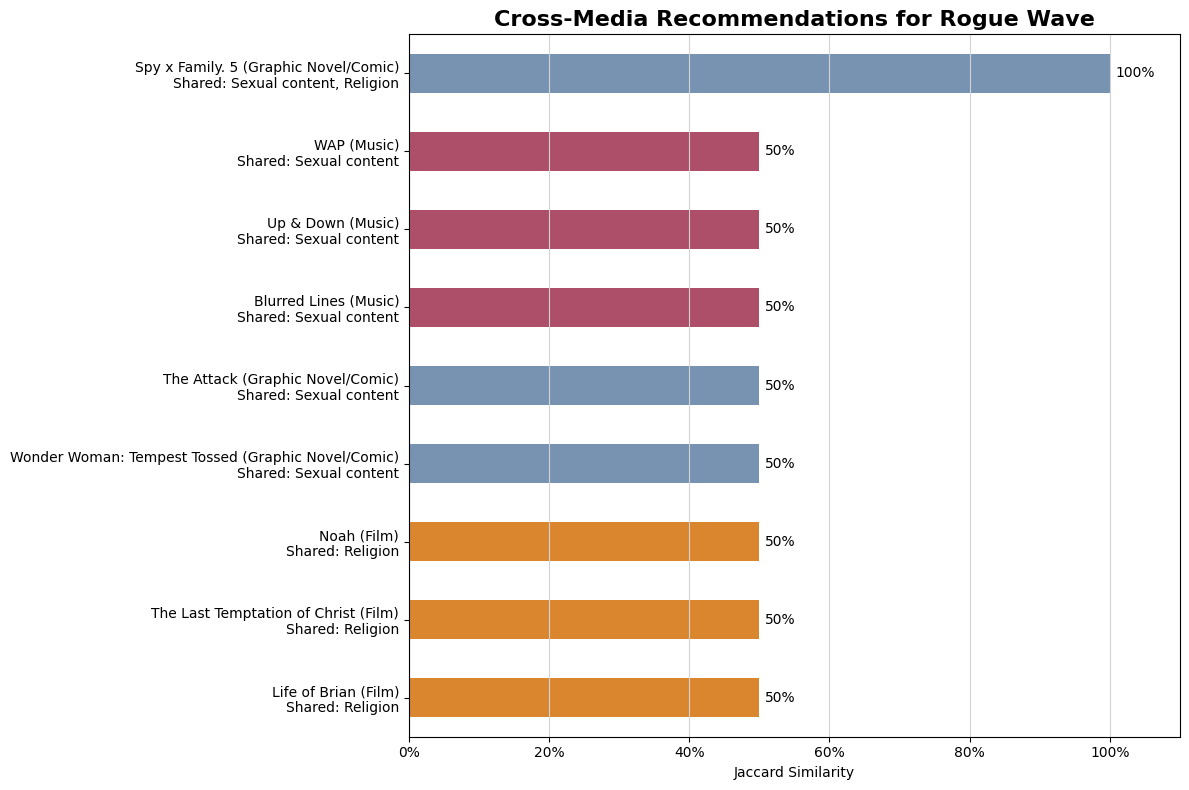

In [30]:
# Prepare the recommendation chart

recommendation_chart = top_recommendations.sort_values(
    "Similarity"
).copy()

recommendation_chart["Label"] = (
    recommendation_chart["Title"]
    + " ("
    + recommendation_chart["Medium"]
    + ")\nShared: "
    + recommendation_chart["Shared Reasons"]
)


# Select colors for each medium

recommendation_colors = recommendation_chart["Medium"].map({
    "Graphic Novel/Comic": "#7892B1",
    "Film": "#D9862F",
    "Music": "#AD4F68"
})


# Create a horizontal bar chart

ax = recommendation_chart.plot.barh(
    x="Label",
    y="Similarity",
    figsize=(12, 8),
    color=recommendation_colors,
    legend=False
)


# Add percentage labels

ax.bar_label(
    ax.containers[0],
    labels=[
        f"{value:.0%}"
        for value in recommendation_chart["Similarity"]
    ],
    padding=4
)


# Add titles and labels

plt.title(
    f"Cross-Media Recommendations for {selected_title}",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Jaccard Similarity")
plt.ylabel("")

ax.set_xlim(0, 1.10)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="x", color="lightgray")
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

## Notes
We built a content-based recommendation algorithm using Jaccard similarity. When a user selects one title, the algorithm compares its censorship reason categories with every record from other media. It then recommends the closest matches and explains which reasons they share. This helps researchers discover connections between censorship cases across Books, Graphic Novels, Films, and Music.

To use the similarity finder, enter a title from the dataset and rerun the following cells. The system returns the three most similar records from each other medium based on shared censorship reason categories. The recommendations support discovery and comparison; they do not measure similarity in plot, artistic content, or censorship severity.

A user or researcher would use it in four steps:
1. Choose a title
   The user enters the title of a Book, Film, Music track, or Graphic Novel/Comic from the dataset.
2. Identify its censorship reasons
   The system reads the record’s seven reason indicators, such as Sexual content, Religion, Language, or Violence and harm.
3. Compare it with other media
   Jaccard similarity compares the selected record with every record from the other media.
4. Review the recommendations
   The system returns the closest matches, their similarity percentages, and the reasons they share.
   
Example

A researcher selects Rogue Wave, which has:
- Sexual content
- Religion
The system recommends:
- Spy x Family. 5 — 100% match
  Shared reasons: Sexual content and Religion
- Life of Brian — 50% match
  Shared reason: Religion
- WAP — 50% match
  Shared reason: Sexual content
  
The researcher can then examine the original reason descriptions and source references to understand how similar objections appeared in different media.

Practical research uses
The tool could help researchers:
- Find cross-media examples for a particular censorship concern
- Compare how the same objection is applied to different forms of expression
- Discover cases they may not have found through title searches
- Build case studies around themes such as religion or sexual content
- Trace every recommendation back to its original source
- Identify areas for additional research

# IV. Conclusions 📚

This project examined how recorded censorship reasons differ across Books, Graphic Novels/Comics, Films, and Music.

The results show that Books and Graphic Novels/Comics have the most similar censorship patterns, with Sexual content and LGBTQIA+ themes appearing most often. Film objections are spread across religion, political and social identity, violence, and sexual content. Music contains more objections involving language and other medium-specific concerns.

We also created a cross-media recommendation algorithm using Jaccard similarity. The algorithm allows a user to select one title and find records from other media with similar censorship reasons. It also explains the shared reasons behind each recommendation.

Overall, the project demonstrates that censorship extends beyond books and that its recorded reasons can vary by medium. Standardizing the data makes these cases easier to compare, explore, and verify.

## Limitations

- The dataset contains 21 selected records from each medium.
- The sample is balanced but is not random or representative of every censorship case.
- The results describe this dataset and do not show which medium is censored most often.
- One record represents approximately 4.8 percentage points, so small differences should be interpreted carefully.
- The recommendation algorithm compares censorship reason categories only. It does not compare stories, artistic content, severity, or cultural context.
- A high similarity score means that two records share reason categories; it does not mean the works themselves are identical.

## Final Takeaway

By combining descriptive analysis with a cross-media similarity tool, this project provides a transparent way to examine censorship patterns and discover related cases across different forms of media.